# Stanford Bunny — Starter Notebook
**Applied Statistics and Data Science I · EN.553.413/613**

**Source:** [The Stanford 3D Scanning Repository](https://graphics.stanford.edu/data/3Dscanrep/), Stanford Computer Graphics Laboratory. Scanned with a Cyberware 3030 MS optical triangulation scanner; the surface was reconstructed with the *zipper* program (Turk & Levoy, 1994). Stanford asks that the repository be acknowledged when the data are used.

The archive `bunny.tar.gz` contains ten raw range scans (`bunny/data/*.ply`) and three reconstructed triangle meshes of a ceramic rabbit figurine (`bunny/reconstruction/`). This notebook uses the full-resolution reconstruction `bun_zipper.ply`: **35,947 vertices** and **69,451 triangles**. The files `bun_zipper_res2.ply` and `bun_zipper_res3.ply` are cruder decimated versions of the same surface (8,171 and 1,889 vertices).

This is not a table of independent observations. Vertices are points on one continuous surface, and nearby vertices are strongly related. The surface is closed and folds back on itself, so it is not a single function $z = f(x, y)$.

Each row of `vertices` is one mesh vertex; each row of `faces` is one triangle.

| Column | Description |
|---|---|
| `x`, `y`, `z` | Vertex position in the reconstruction's coordinate system (units not documented; the model is about 0.15–0.16 across, consistent with metres) |
| `confidence` | Scanner confidence for the vertex, between 0 and 1 |
| `intensity` | Reflectance value; equal to 0.5 for nearly every vertex, so it carries little information |
| `v0`, `v1`, `v2` (in `faces`) | Row indices into `vertices` of a triangle's three corners |

This notebook only loads the data and makes a few basic plots. The analysis is up to you.

> The first run downloads the archive (about 5 MB, internet required) and saves it in a local `data/` folder.

## 1. Load the data

In [1]:
from pathlib import Path
import io
import tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA = Path('data')
DATA.mkdir(exist_ok=True)
ARCHIVE = DATA / 'bunny.tar.gz'
URL = 'https://graphics.stanford.edu/pub/3Dscanrep/bunny.tar.gz'

if not ARCHIVE.is_file():
    r = requests.get(URL, timeout=120)
    r.raise_for_status()
    ARCHIVE.write_bytes(r.content)


def read_ply(member):
    # Read an ASCII PLY file from the archive into vertex and face tables.
    with tarfile.open(ARCHIVE, 'r:gz') as tar:
        text = tar.extractfile(member).read().decode('ascii')
    header, body = text.split('end_header\n', 1)
    n_vertices = n_faces = 0
    vertex_cols = []
    for line in header.splitlines():
        parts = line.split()
        if parts[:2] == ['element', 'vertex']:
            n_vertices = int(parts[2])
        elif parts[:2] == ['element', 'face']:
            n_faces = int(parts[2])
        elif parts[0] == 'property' and parts[1] != 'list':
            vertex_cols.append(parts[-1])
    lines = body.splitlines()
    vertices = pd.read_csv(io.StringIO('\n'.join(lines[:n_vertices])), sep=r'\s+',
                           header=None, names=vertex_cols)
    faces = pd.read_csv(io.StringIO('\n'.join(lines[n_vertices:n_vertices + n_faces])), sep=r'\s+',
                        header=None, names=['n', 'v0', 'v1', 'v2']).drop(columns='n')
    return vertices, faces


vertices, faces = read_ply('bunny/reconstruction/bun_zipper.ply')
print('vertices:', vertices.shape, ' faces:', faces.shape)
vertices.head()

vertices: (35947, 5)  faces: (69451, 3)


,x,y,z,confidence,intensity
0,-0.037830,0.127940,0.004475,0.850855,0.5
1,-0.044779,0.128887,0.001905,0.900159,0.5
2,-0.068010,0.151244,0.037195,0.398443,0.5
3,-0.002287,0.130150,0.023220,0.852680,0.5
4,-0.022605,0.126675,0.007156,0.675938,0.5


In [2]:
vertices.describe().T

,count,mean,std,min,25%,50%,75%,max
x,35947.0,-0.026760,0.040988,-0.094690,-0.062496,-0.030517,0.006512,0.061009
y,35947.0,0.095216,0.041532,0.032987,0.059578,0.093396,0.126198,0.187321
z,35947.0,0.008947,0.028165,-0.061874,-0.014351,0.008165,0.035099,0.058800
confidence,35947.0,0.577079,0.168709,0.000000,0.471253,0.592026,0.696159,0.999238
intensity,35947.0,0.481677,0.054626,0.000000,0.500000,0.500000,0.500000,0.500000


In [3]:
# Everything in the archive
with tarfile.open(ARCHIVE, 'r:gz') as tar:
    for m in tar.getmembers():
        if m.isfile():
            print(f'{m.size/1e6:6.2f} MB  {m.name}')

  0.00 MB  bunny/data/README
  0.00 MB  bunny/data/bun.conf
  0.00 MB  bunny/data/bun.conf~
  1.99 MB  bunny/data/bun000.ply
  1.97 MB  bunny/data/bun045.ply
  1.65 MB  bunny/data/bun090.ply
  1.98 MB  bunny/data/bun180.ply
  1.68 MB  bunny/data/bun270.ply
  1.81 MB  bunny/data/bun315.ply
  1.86 MB  bunny/data/chin.ply
  1.69 MB  bunny/data/ear_back.ply
  1.90 MB  bunny/data/top2.ply
  1.83 MB  bunny/data/top3.ply
  0.00 MB  bunny/reconstruction/README
  3.03 MB  bunny/reconstruction/bun_zipper.ply
  0.66 MB  bunny/reconstruction/bun_zipper_res2.ply
  0.15 MB  bunny/reconstruction/bun_zipper_res3.ply
  0.03 MB  bunny/reconstruction/bun_zipper_res4.ply


## 2. A first look

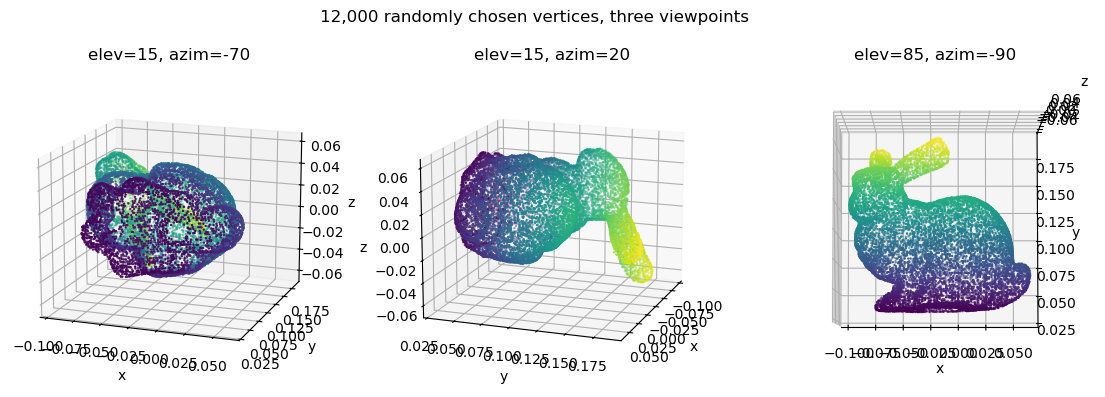

In [4]:
xyz = vertices[['x', 'y', 'z']].to_numpy()
rng = np.random.default_rng(0)
show = rng.choice(len(xyz), 12000, replace=False)

fig = plt.figure(figsize=(14, 4.5))
for k, (elev, azim) in enumerate([(15, -70), (15, 20), (85, -90)]):
    ax = fig.add_subplot(1, 3, k + 1, projection='3d')
    ax.scatter(xyz[show, 0], xyz[show, 1], xyz[show, 2], c=xyz[show, 1], s=0.5, cmap='viridis')
    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect(np.ptp(xyz, axis=0))
    ax.set(xlabel='x', ylabel='y', zlabel='z', title=f'elev={elev}, azim={azim}')
fig.suptitle('12,000 randomly chosen vertices, three viewpoints')
plt.show()

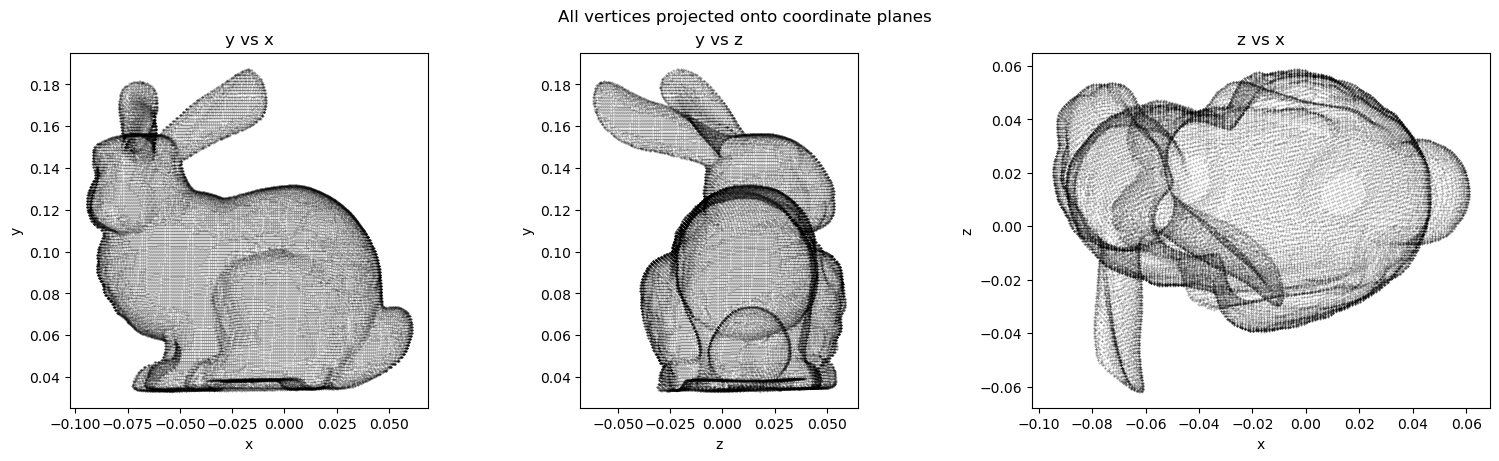

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, (a, b) in zip(axs, [('x', 'y'), ('z', 'y'), ('x', 'z')]):
    ax.scatter(vertices[a], vertices[b], s=0.2, alpha=0.3, color='k')
    ax.set(xlabel=a, ylabel=b, title=f'{b} vs {a}', aspect='equal')
fig.suptitle('All vertices projected onto coordinate planes')
plt.show()

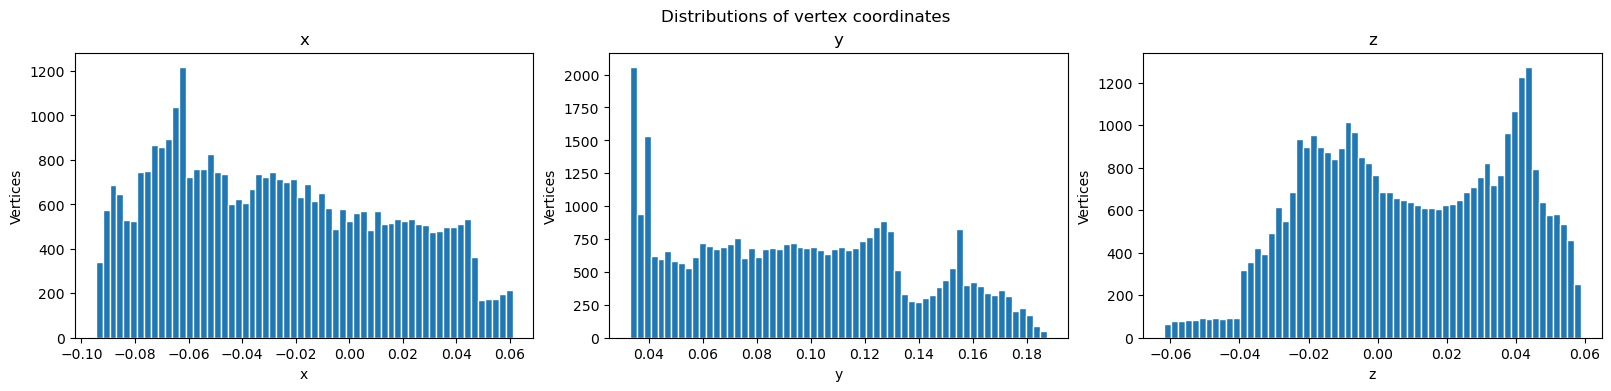

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), constrained_layout=True)
for ax, col in zip(axs, ['x', 'y', 'z']):
    ax.hist(vertices[col], bins=60, edgecolor='white')
    ax.set(xlabel=col, ylabel='Vertices', title=col)
fig.suptitle('Distributions of vertex coordinates')
plt.show()

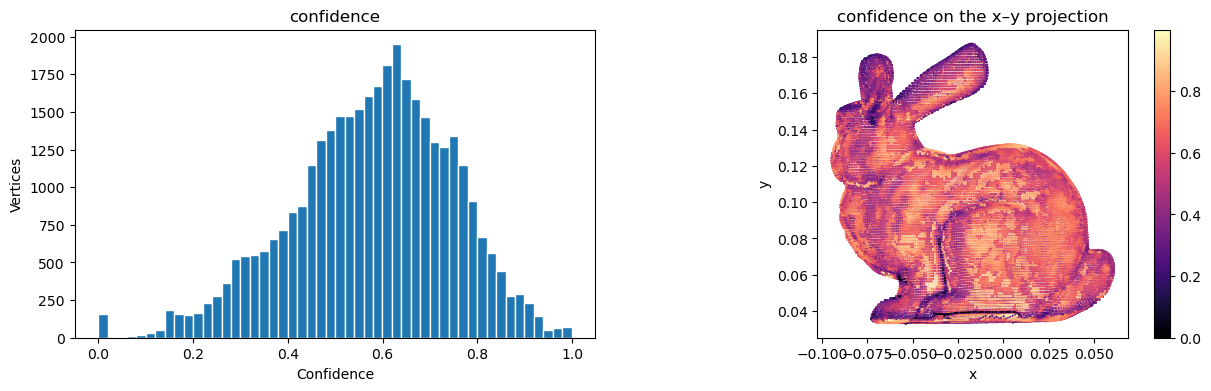

intensity
0.500000    28228
0.000000      232
0.464351        3
0.482046        3
0.463847        3
Name: count, dtype: int64


In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].hist(vertices['confidence'], bins=50, edgecolor='white')
axs[0].set(xlabel='Confidence', ylabel='Vertices', title='confidence')
sc = axs[1].scatter(vertices['x'], vertices['y'], c=vertices['confidence'], s=0.3, cmap='magma')
axs[1].set(xlabel='x', ylabel='y', title='confidence on the x–y projection', aspect='equal')
fig.colorbar(sc, ax=axs[1])
plt.show()
print(vertices['intensity'].value_counts().head())

Total surface area: 0.0571 (squared coordinate units)


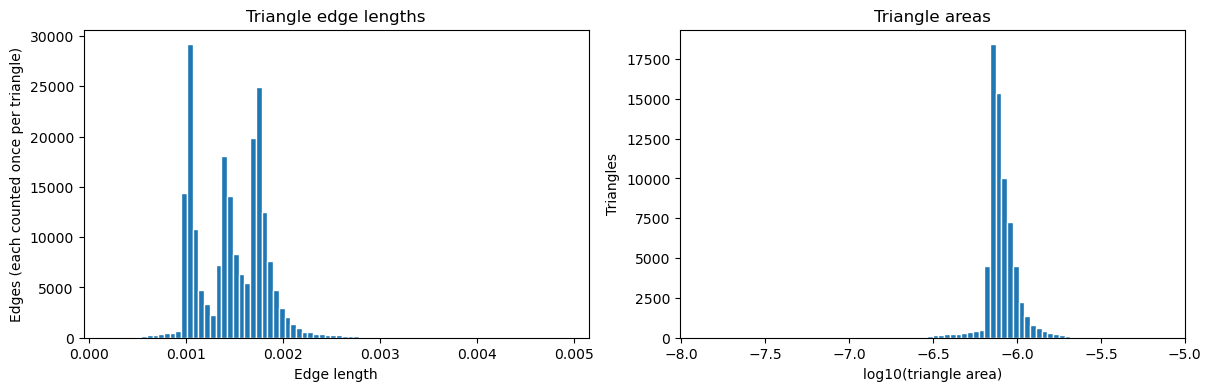

In [8]:
# Triangle sizes: how evenly do the vertices cover the surface?
p0, p1, p2 = (xyz[faces[c]] for c in ['v0', 'v1', 'v2'])
area = 0.5 * np.linalg.norm(np.cross(p1 - p0, p2 - p0), axis=1)
edges = np.concatenate([np.linalg.norm(p1 - p0, axis=1),
                        np.linalg.norm(p2 - p1, axis=1),
                        np.linalg.norm(p0 - p2, axis=1)])
print(f'Total surface area: {area.sum():.4f} (squared coordinate units)')

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].hist(edges, bins=80, edgecolor='white')
axs[0].set(xlabel='Edge length', ylabel='Edges (each counted once per triangle)', title='Triangle edge lengths')
axs[1].hist(np.log10(area[area > 0]), bins=80, edgecolor='white')
axs[1].set(xlabel='log10(triangle area)', ylabel='Triangles', title='Triangle areas')
plt.show()

## 3. Your exploration
Add your own analysis below.